# Chimera v2.4 — Paper-quality model validation

This notebook walks through **every pre-registered expectation** (E1–E7, 32
checks) on a single trained Chimera run, producing publication-quality
figures for each. The same notebook is also the **diagnostic template**: if a
model run fails an expectation, the corresponding panel below will make the
failure visible.

Sections map 1:1 to the expectation categories in
[`training/workflow.md`](../training/workflow.md):

| Section | Category | # checks |
|---|---|---|
| §1 | E1 — Pretraining / data sanity | 5 |
| §2 | E2 — Training dynamics | 8 |
| §3 | E3 — GIN behaviour | 6 |
| §4 | E4 — α biology | 3 |
| §5 | E5 — Shared decoder / residual | 3 |
| §6 | E6 — z-leakage / adversarial | 3 |
| §7 | E7 — Convergence | 4 |
| §8 | Round2 supplements (beyond the 32 gates) | — |
| §9 | Final pass/fail table | — |

Figures are rendered at 220 dpi; the matplotlib style is set to a
Nature-like look in `_paper_utils.set_paper_style`.

> **Default run:** `iter16-slow-classifier` (Human + Monkey, 2-species,
> 100 epochs, 32/32). To validate a different run, change the `RUN_NAME`
> constant in the next cell.


In [1]:
import sys
from pathlib import Path

HERE = Path.cwd()
sys.path.insert(0, str(HERE))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import seaborn as sns
from scipy import stats as spstats

import _paper_utils as pu
pu.set_paper_style()

# --------- pick the run to validate ---------
RUN_NAME = "iter31-mmd1k-masked-detached"  # try: "iter21-4sp-advw200-fb1" for 4-sp
SAVE_FIGS = False                    # set True to write PNGs next to the run
# --------------------------------------------

run = pu.load_run(RUN_NAME)
fs = run["final_state"]
metrics = run.get("metrics")
snapshots = run.get("snapshots", [])
cfg = run["config"]
summary = run.get("summary", {})

n_species = int(fs["n_species"])
n_batch = int(fs["n_batch"])
n_cells = int(fs["n_cells"])
n_genes = int(fs["alpha"].shape[0])
chance = 1.0 / n_species

adata = pu.load_adata_for_run(run)
species_names = list(adata.obs["species"].astype("category").cat.categories)
sp_palette = pu.species_colors(species_names)

def cfg_get(key, default=None):
    if cfg.get(key) is not None:
        return cfg[key]
    pk = cfg.get("plan_kwargs", {}) or {}
    return pk.get(key, default)

adv_weight_val = cfg_get("adv_weight", 100.0)
adv_lr_val = cfg_get("adv_lr", 1e-4)
lam_fit_val = cfg_get("lambda_fit", 0.01)
lam_anchor_val = cfg_get("lambda_anchor", 0.001)
lam_res_val = cfg_get("lambda_res", 0.01)

print(f"run:      {RUN_NAME}")
print(f"config:   {cfg.get('ablation_config', '?')} | "
      f"adv_weight={adv_weight_val} | adv_lr={adv_lr_val} | "
      f"λ_fit={lam_fit_val} λ_anchor={lam_anchor_val} λ_res={lam_res_val}")
print(f"epochs:   max={cfg.get('max_epochs')}  seed={cfg.get('seed')}")
print(f"data:     N={n_cells:,} cells  G={n_genes:,} genes  K={n_species} species  "
      f"B={n_batch} batches")
print(f"species:  {species_names}")
if summary:
    s = summary["expectation_summary"]
    print(f"gates:    {s['pass']}/{s['pass']+s['fail']+s['skip']} passed "
          f"({s['fail']} failed, {s['skip']} skipped)")

FIG_DIR = run["run_dir"] / "paper_figures"
if SAVE_FIGS:
    FIG_DIR.mkdir(parents=True, exist_ok=True)


run:      iter31-mmd1k-masked-detached
config:   D | adv_weight=100.0 | adv_lr=0.0001 | λ_fit=0.1 λ_anchor=0.001 λ_res=0.01
epochs:   max=100  seed=42
data:     N=12,608 cells  G=8,430 genes  K=2 species  B=3 batches
species:  ['Human', 'Monkey']


In [2]:
def savefig(fig, name: str):
    if SAVE_FIGS:
        fig.savefig(FIG_DIR / f"{name}.png", dpi=220, bbox_inches="tight")
        fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")

def verdict(passed: bool, note: str = "") -> str:
    mark = "✓ PASS" if passed else "✗ FAIL"
    return f"**{mark}** {note}"


## §1 — E1 · Data / pretraining sanity

The inputs to training must be sane before any loss can be interpreted.
These five checks verify: (E1.1) the conservation prior carries biological
signal (or the ESM-2-only regime is declared), (E1.2) GIN features are
unit-variance, (E1.3) p_null is in a reasonable dynamic range (not all-zero
or all-one), (E1.4) every batch maps to exactly one species, (E1.5) the
conservation prior spans a usable range.

*Round2 cites:* critical_reexamination §95–96, §124, §452 ; implementation
prompt's p_null Laplace smoothing.


/var/folders/y7/7c17s0l57szdjc1cdc9dmnpm0000gn/T/ipykernel_17726/3814396804.py:53: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


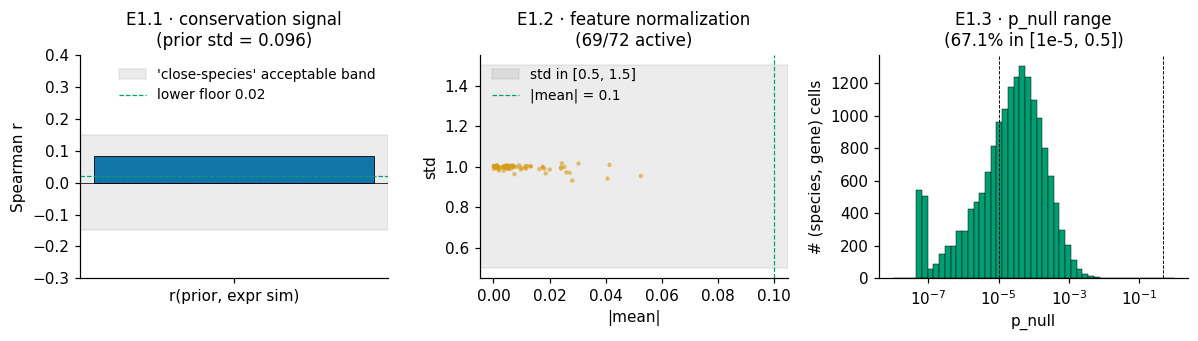

E1.1: **✓ PASS** (r=+0.083)
E1.2: **✓ PASS** (n_active=69/72)
E1.3: **✓ PASS** (frac=67.1%)
E1.4: **✓ PASS** (max species/batch=1)
E1.5: **✓ PASS** (std=0.096)


In [3]:
pc = run["pretrain_checks"]

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))

# --- E1.1 conservation signal -----------------------------------------------
e11 = pc["E1.1_conservation_signal"]
r = e11.get("spearman_r") or e11.get("value") or 0.0
prior_std = e11.get("prior_std")
ax = axes[0]
ax.axhline(0, color="k", lw=0.5)
ax.bar(["r(prior, expr sim)"], [r],
       color="#0072B2", edgecolor="k", lw=0.6)
ax.axhspan(-0.15, 0.15, color="grey", alpha=0.15,
           label="'close-species' acceptable band")
ax.axhline(0.02, ls="--", color="#009E73", lw=0.8, label="lower floor 0.02")
ax.set_ylim(-0.3, 0.4)
ax.set_ylabel("Spearman r")
ax.set_title(f"E1.1 · conservation signal\n(prior std = {prior_std:.3f})" if prior_std is not None else "E1.1 · conservation signal")
ax.legend(loc="upper right")

# --- E1.2 feature normalization ---------------------------------------------
e12 = pc["E1.2_gene_features_normalized"]
# feature stats on live GIN features
gf = adata.varm["gene_features"]
means = np.abs(gf.mean(axis=0))
stds = gf.std(axis=0)
active = stds > 1e-6
ax = axes[1]
ax.scatter(means[active], stds[active], s=8, alpha=0.6, color="#E69F00", edgecolors="none")
ax.axhspan(0.5, 1.5, color="grey", alpha=0.15, label="std in [0.5, 1.5]")
ax.axvline(0.1, ls="--", color="#009E73", lw=0.8, label="|mean| = 0.1")
ax.set_xlabel("|mean|")
ax.set_ylabel("std")
ax.set_title(f"E1.2 · feature normalization\n({int(active.sum())}/{len(stds)} active)")
ax.legend()

# --- E1.3 p_null dynamic range ----------------------------------------------
e13 = pc["E1.3_p_null_dynamic_range"]
p_null = adata.uns["p_null"]
p_flat = np.ravel(p_null)
ax = axes[2]
bins = np.logspace(-8, 0, 50)
ax.hist(p_flat[p_flat > 0], bins=bins, color="#009E73",
        edgecolor="k", lw=0.3)
for t in (1e-5, 0.5):
    ax.axvline(t, color="k", ls="--", lw=0.6)
ax.set_xscale("log")
ax.set_xlabel("p_null")
ax.set_ylabel("# (species, gene) cells")
frac = e13.get("value") or e13.get("frac_in_range_1e-5_to_5e-1")
ax.set_title(f"E1.3 · p_null range\n({float(frac):.1%} in [1e-5, 0.5])")

plt.tight_layout()
savefig(fig, "fig_e1_data_sanity")
plt.show()

# verdicts
print("E1.1:", verdict(bool(e11.get("pass")), f"(r={r:+.3f})"))
print("E1.2:", verdict(bool(e12.get("pass")), f"(n_active={e12.get('n_active_features')}/{gf.shape[1]})"))
print("E1.3:", verdict(bool(e13.get("pass")), f"(frac={float(frac):.1%})"))
print("E1.4:", verdict(bool(pc['E1.4_batch_to_species_unique'].get("pass")),
                     f"(max species/batch={pc['E1.4_batch_to_species_unique'].get('max_species_per_batch')})"))
print("E1.5:", verdict(bool(pc['E1.5_conservation_prior_range'].get("pass")),
                     f"(std={pc['E1.5_conservation_prior_range'].get('std'):.3f})"))


## §2 — E2 · Training dynamics

Loss components, warmup schedules, and the per-term calibration ratios
required to avoid FM1/FM3. The panels: (a) the six loss components over
epochs, (b) warmup schedules (KL, FQR, adversarial), (c) calibration
ratios `λ·L_term / L_recon` inside the round2-safe bands.

*Round2 cites:* critical_reexamination §10 (loss-scale bug), §1425 (KL warmup),
BEG §17–19 (warmup notes), OAI §898 (ELBO plateau).


/var/folders/y7/7c17s0l57szdjc1cdc9dmnpm0000gn/T/ipykernel_17726/1699147299.py:43: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=8)


/var/folders/y7/7c17s0l57szdjc1cdc9dmnpm0000gn/T/ipykernel_17726/1699147299.py:66: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


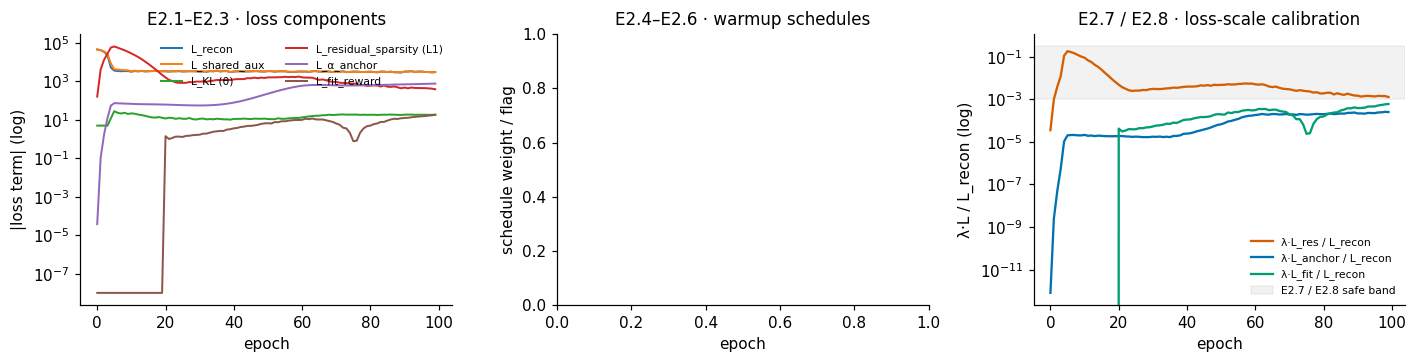

| E2.1 | loss_finite | E2 dynamics | True | no NaN/Inf | ✓ |
| E2.2 | loss_decreases | E2 dynamics | first=57820.324, last=4248.321 | last < first | ✓ |
| E2.3 | L_recon_drops | E2 dynamics | epoch1=42395.711, epoch20=3402.138, drop=91.98% | ≥10% | ✓ |
| E2.4 | kl_warms_up | E2 dynamics | monotonic | non-decreasing | ✓ |
| E2.5 | fqr_activates | E2 dynamics | active at epoch 20 | 1 at epoch ≥ 20 | ✓ |
| E2.6 | adv_activates | E2 dynamics | active at epoch 5 | 1 at epoch ≥ 5 | ✓ |
| E2.7 | L1_scale_ok | E2 dynamics | ratio=0.0064 (last 5 post-25) | [1e-3, 0.3] | ✓ |
| E2.8 | anchor_scale_ok | E2 dynamics | ratio=0.001258 | [1e-5, 0.3] | ✓ |


In [4]:
df = metrics.copy()
df = df[df["epoch"].notna()].copy()
df["epoch"] = df["epoch"].astype(int)

# Collapse multiple rows per epoch (Lightning emits one row per batch + one per epoch)
loss_cols = [c for c in df.columns if c.startswith("train/") or c in ("train_loss_epoch", "validation_loss")]
dfe = df.groupby("epoch")[loss_cols].mean(numeric_only=True).reset_index()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))

# --- (a) loss component curves ---
ax = axes[0]
loss_map = {
    "train/L_recon": "L_recon",
    "train/L_shared_aux": "L_shared_aux",
    "train/L_kl": "L_KL (θ)",
    "train/L_residual_sparsity": "L_residual_sparsity (L1)",
    "train/L_alpha_anchor": "L_α_anchor",
    "train/L_fit_reward": "L_fit_reward",
}
colors = sns.color_palette("tab10", n_colors=len(loss_map))
for (col, label), c in zip(loss_map.items(), colors):
    if col in dfe.columns:
        s = dfe[col]
        ax.plot(dfe["epoch"], s.abs() + 1e-8, label=label, color=c, lw=1.3)
ax.set_yscale("log")
ax.set_xlabel("epoch")
ax.set_ylabel("|loss term| (log)")
ax.set_title("E2.1–E2.3 · loss components")
ax.legend(fontsize=7, ncol=2, loc="upper right")

# --- (b) schedule warmups ---
ax = axes[1]
sched_cols = [c for c in df.columns if c.startswith("schedule/")]
for col in sched_cols:
    s = dfe.get(col)
    if s is None or s.isna().all():
        continue
    ax.plot(dfe["epoch"], s, label=col.replace("schedule/", ""), lw=1.2)
ax.set_xlabel("epoch")
ax.set_ylabel("schedule weight / flag")
ax.set_title("E2.4–E2.6 · warmup schedules")
ax.legend(fontsize=8)

# --- (c) calibration ratios ---
ax = axes[2]
lam_res = float(lam_res_val)
lam_anchor = float(lam_anchor_val)
lam_fit = float(lam_fit_val)

recon = dfe["train/L_recon"].abs().replace(0, np.nan)
rat_res = (lam_res * dfe["train/L_residual_sparsity"].abs()) / recon
rat_anch = (lam_anchor * dfe["train/L_alpha_anchor"].abs()) / recon
rat_fit = (lam_fit * dfe["train/L_fit_reward"].abs()) / recon

ax.plot(dfe["epoch"], rat_res, label="λ·L_res / L_recon", color="#D55E00")
ax.plot(dfe["epoch"], rat_anch, label="λ·L_anchor / L_recon", color="#0072B2")
ax.plot(dfe["epoch"], rat_fit, label="λ·L_fit / L_recon", color="#009E73")
ax.axhspan(1e-3, 0.3, color="grey", alpha=0.10, label="E2.7 / E2.8 safe band")
ax.set_yscale("log")
ax.set_xlabel("epoch")
ax.set_ylabel("λ·L / L_recon (log)")
ax.set_title("E2.7 / E2.8 · loss-scale calibration")
ax.legend(fontsize=7)

plt.tight_layout()
savefig(fig, "fig_e2_training_dynamics")
plt.show()

# Verdicts from the run's report (already computed by check_expectations.py)
print("\n".join([l for l in run.get("report_md", "").splitlines() if "| E2." in l][:10]))


## §3 — E3 · GIN behaviour

Six checks on the Gene Integration Network: (E3.1) α initializes at the
prior; (E3.2) α histogram is a healthy continuous distribution, not pinned
at 0 or 1; (E3.3) no bimodal collapse around prior + ~0 (FM3 signature);
(E3.4) Δα is two-sided (FM4 signature); (E3.5) |correction| has non-zero
magnitude; (E3.6) α evolves from init — the GIN is alive.

*Round2 cites:* CRE §116 (zero-init), §440 (bimodal FM3), §497 (one-sided
FM4), §1498 Caveat 28 (correction magnitude), §1585 FM-C (dead GIN),
BEG §323 (α histogram shapes).


/var/folders/y7/7c17s0l57szdjc1cdc9dmnpm0000gn/T/ipykernel_17726/3358711940.py:96: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


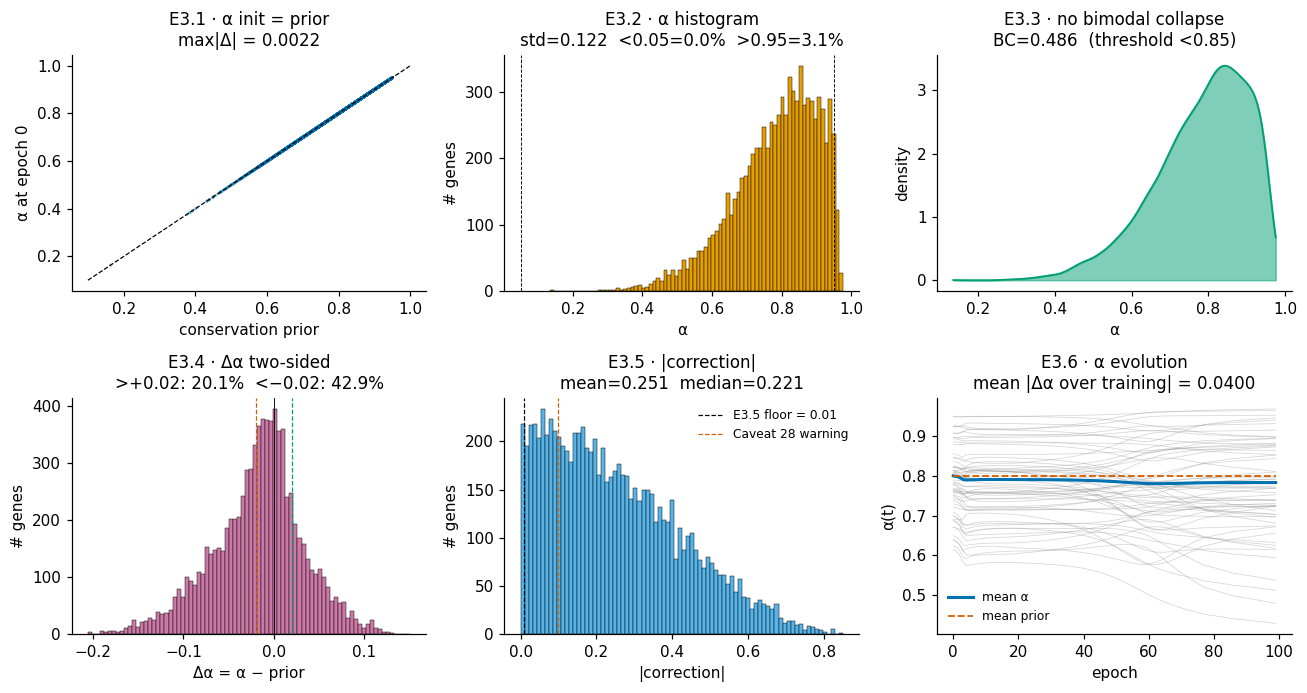

| E3.1 | alpha_init_is_prior | E3 GIN | max|α-prior| at first snapshot = 0.0022 | ≤ 0.05 (post-epoch-0) | ✓ |
| E3.2 | alpha_histogram_healthy | E3 GIN | std=0.122, frac<0.05=0.00%, frac>0.95=3.13% | std≥0.05, each tail ≤50% | ✓ |
| E3.3 | alpha_no_bimodal_collapse | E3 GIN | BC=0.486 | < 0.85 | ✓ |
| E3.4 | delta_alpha_two_sided | E3 GIN | Δα>0.02 20.07%, Δα<-0.02 42.92% | both ≥5% | ✓ |
| E3.5 | correction_nonzero | E3 GIN | mean|correction|=0.2506 | ≥0.01 | ✓ |
| E3.6 | gin_learning_evolved | E3 GIN | mean|Δα over training| = 0.0400 | ≥0.01 | ✓ |


In [5]:
alpha = fs["alpha"]
prior = fs["prior"]
dalpha = alpha - prior
corr = fs["correction"]

# alpha@init from the first snapshot (epoch 0)
alpha0 = snapshots[0]["alpha"] if snapshots else alpha.copy()
alpha_end = snapshots[-1]["alpha"] if snapshots else alpha.copy()
init_err = float(np.abs(alpha0 - prior).max())

# bimodality coefficient
def bimodality_coef(x):
    x = np.asarray(x, dtype=np.float64).ravel()
    n = x.size
    if n < 3:
        return 0.0
    z = (x - x.mean()) / x.std(ddof=1)
    g1, g2 = (z ** 3).mean(), (z ** 4).mean() - 3.0
    return (g1 ** 2 + 1) / (g2 + 3 * (n - 1) ** 2 / ((n - 2) * (n - 3) + 1e-12))

bc = bimodality_coef(alpha)
frac_pos = float((dalpha > 0.02).mean())
frac_neg = float((dalpha < -0.02).mean())

fig, axes = plt.subplots(2, 3, figsize=(12, 6.4))

# (E3.1) alpha@init vs prior
ax = axes[0, 0]
ax.scatter(prior, alpha0, s=4, color="#0072B2", alpha=0.4, edgecolors="none")
lims = [0.1, 1.0]
ax.plot(lims, lims, color="k", lw=0.8, ls="--")
ax.set_xlabel("conservation prior")
ax.set_ylabel("α at epoch 0")
ax.set_title(f"E3.1 · α init = prior\nmax|Δ| = {init_err:.4f}")

# (E3.2) alpha histogram
ax = axes[0, 1]
ax.hist(alpha, bins=80, color="#E69F00", edgecolor="k", lw=0.3)
ax.axvline(0.05, ls="--", color="k", lw=0.6)
ax.axvline(0.95, ls="--", color="k", lw=0.6)
ax.set_xlabel("α")
ax.set_ylabel("# genes")
ax.set_title(f"E3.2 · α histogram\nstd={alpha.std():.3f}  "
             f"<0.05={(alpha<0.05).mean():.1%}  >0.95={(alpha>0.95).mean():.1%}")

# (E3.3) bimodality coefficient: density plot of alpha
ax = axes[0, 2]
kde_x = np.linspace(alpha.min(), alpha.max(), 400)
kde = spstats.gaussian_kde(alpha)(kde_x)
ax.fill_between(kde_x, kde, color="#009E73", alpha=0.5)
ax.plot(kde_x, kde, color="#009E73", lw=1.2)
ax.set_xlabel("α")
ax.set_ylabel("density")
ax.set_title(f"E3.3 · no bimodal collapse\nBC={bc:.3f}  (threshold <0.85)")

# (E3.4) delta-alpha histogram
ax = axes[1, 0]
ax.hist(dalpha, bins=80, color="#CC79A7", edgecolor="k", lw=0.3)
ax.axvline(0, color="k", lw=0.6)
ax.axvline(0.02, color="#009E73", lw=0.8, ls="--")
ax.axvline(-0.02, color="#D55E00", lw=0.8, ls="--")
ax.set_xlabel("Δα = α − prior")
ax.set_ylabel("# genes")
ax.set_title(f"E3.4 · Δα two-sided\n>+0.02: {frac_pos:.1%}  <−0.02: {frac_neg:.1%}")

# (E3.5) |correction| histogram
ax = axes[1, 1]
ax.hist(np.abs(corr), bins=80, color="#56B4E9", edgecolor="k", lw=0.3)
ax.axvline(0.01, color="k", ls="--", lw=0.8, label="E3.5 floor = 0.01")
ax.axvline(0.10, color="#D55E00", ls="--", lw=0.8, label="Caveat 28 warning")
ax.set_xlabel("|correction|")
ax.set_ylabel("# genes")
ax.set_title(f"E3.5 · |correction|\nmean={np.abs(corr).mean():.3f}  median={np.median(np.abs(corr)):.3f}")
ax.legend(fontsize=8)

# (E3.6) alpha trajectory (a few genes)
ax = axes[1, 2]
if snapshots:
    traj = pu.collect_alpha_trajectory(snapshots)
    rng = np.random.default_rng(0)
    pick = rng.choice(n_genes, size=min(60, n_genes), replace=False)
    for gi in pick:
        ax.plot(traj["epochs"], traj["alpha"][:, gi], color="#888888", lw=0.5, alpha=0.35)
    ax.plot(traj["epochs"], traj["alpha"].mean(axis=1), color="#0072B2", lw=2, label="mean α")
    ax.plot(traj["epochs"], prior.mean() * np.ones_like(traj["epochs"]),
            color="#D55E00", lw=1.2, ls="--", label="mean prior")
    ax.set_xlabel("epoch")
    ax.set_ylabel("α(t)")
    ax.set_title(f"E3.6 · α evolution\nmean |Δα over training| = "
                 f"{np.abs(traj['alpha'][-1] - traj['alpha'][0]).mean():.4f}")
    ax.legend(fontsize=8)
else:
    ax.text(0.5, 0.5, "no snapshots", ha="center", va="center",
            transform=ax.transAxes)

plt.tight_layout()
savefig(fig, "fig_e3_gin")
plt.show()

for line in run.get("report_md", "").splitlines():
    if "| E3." in line:
        print(line)


## §4 — E4 · α biology

At this stage we check that α is *biologically sensible*: (E4.1) correlates
with the conservation prior rather than being random; (E4.2) the canonical
L-shape — low-α genes have large residual, high-α genes have essentially
zero residual; (E4.3) the FQR term has on-signal on at least some genes.

*Round2 cites:* OAI §1247 (alpha-prior correlation target), §1338 (L-shape),
§902 (S_g fraction), BEG §320–322.


/var/folders/y7/7c17s0l57szdjc1cdc9dmnpm0000gn/T/ipykernel_17726/3560429994.py:37: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


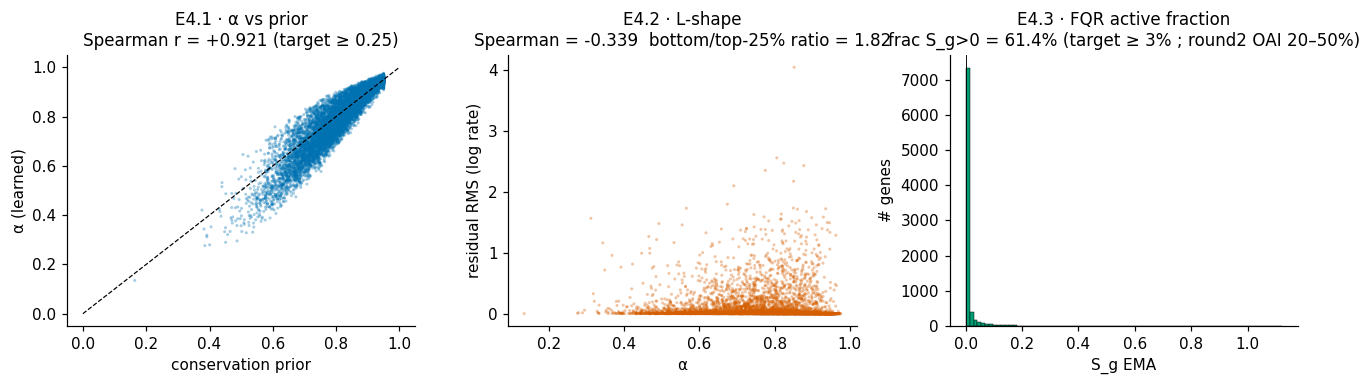

| E4.1 | alpha_correlates_prior | E4 biology | Spearman r=0.921 | ≥0.25 | ✓ |
| E4.2 | residual_alpha_l_shape | E4 biology | Spearman=-0.331, low/high ratio=2.02 (Pearson=-0.078) | Spearman ≤ -0.15 OR low25%/top25% residual ratio ≥ 1.5 | ✓ |
| E4.3 | fqr_active_fraction | E4 biology | frac S_g>0 = 61.42% | ≥3% | ✓ |


In [6]:
S_g = fs["S_g_ema"]
res_rms = fs["residual_rms"]

spearman_prior = spstats.spearmanr(alpha, prior).correlation
spearman_l = spstats.spearmanr(alpha, res_rms).correlation
low_q, high_q = np.quantile(alpha, [0.25, 0.75])
low_mask = alpha <= low_q
high_mask = alpha >= high_q
ratio_low_high = res_rms[low_mask].mean() / max(res_rms[high_mask].mean(), 1e-9)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))

# E4.1 alpha vs prior
ax = axes[0]
ax.scatter(prior, alpha, s=4, color="#0072B2", alpha=0.35, edgecolors="none")
ax.plot([0, 1], [0, 1], color="k", lw=0.8, ls="--")
ax.set_xlabel("conservation prior")
ax.set_ylabel("α (learned)")
ax.set_title(f"E4.1 · α vs prior\nSpearman r = {spearman_prior:+.3f} (target ≥ 0.25)")

# E4.2 L-shape
ax = axes[1]
ax.scatter(alpha, res_rms, s=4, color="#D55E00", alpha=0.35, edgecolors="none")
ax.set_xlabel("α")
ax.set_ylabel("residual RMS (log rate)")
ax.set_title(f"E4.2 · L-shape\nSpearman = {spearman_l:+.3f}  bottom/top-25% ratio = {ratio_low_high:.2f}")

# E4.3 S_g histogram
ax = axes[2]
ax.hist(S_g, bins=80, color="#009E73", edgecolor="k", lw=0.3)
ax.axvline(0, color="k", lw=0.6)
frac_sg_pos = float((S_g > 0).mean())
ax.set_xlabel("S_g EMA")
ax.set_ylabel("# genes")
ax.set_title(f"E4.3 · FQR active fraction\nfrac S_g>0 = {frac_sg_pos:.1%} (target ≥ 3% ; round2 OAI 20–50%)")

plt.tight_layout()
savefig(fig, "fig_e4_alpha_biology")
plt.show()

for line in run.get("report_md", "").splitlines():
    if "| E4." in line:
        print(line)


## §5 — E5 · Shared decoder + residual

Three checks on the dual-head decoder: (E5.1) `L_shared_aux` drops during
training (not stuck at random init — FM2 screen); (E5.2) `mu_shared_only`
varies across genes (not a constant-output predictor); (E5.3) the residual
head has nonzero but bounded magnitude (not dead, not exploding).

*Round2 cites:* CRE §316–359 (shared decoder loss), §1590 FM-D (shared
collapse), OAI §1337 (residual magnitude), §1340 (shared ≠ constant).


/var/folders/y7/7c17s0l57szdjc1cdc9dmnpm0000gn/T/ipykernel_17726/1582100855.py:37: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


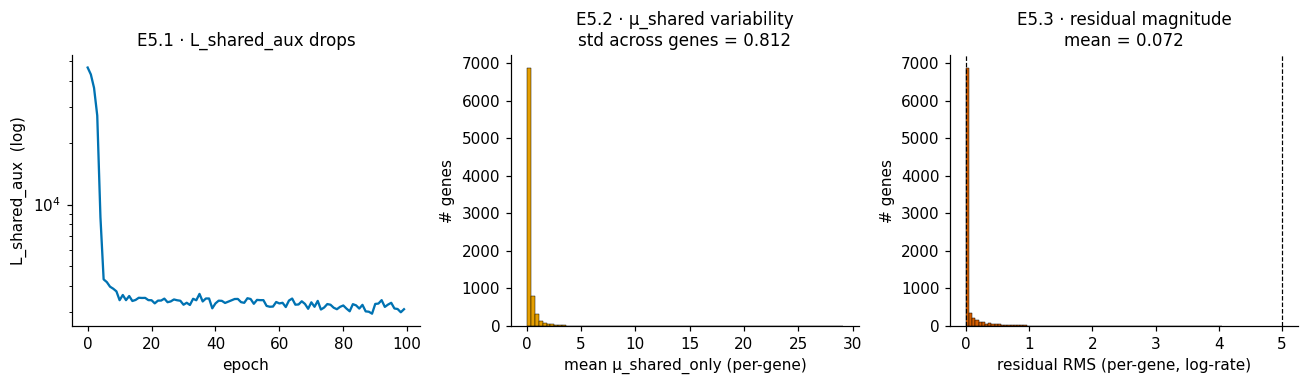

| E5.2 | mu_shared_has_variance | E5 shared/residual | std(mean over cells) = 0.8122 | ≥0.01 | ✓ |
| E5.3 | residual_has_magnitude | E5 shared/residual | RMS log-rate = 0.2227 | in [0.01, 5] | ✓ |
| E5.1 | L_shared_aux_drops | E5 shared/residual | epoch1=42968.906, epoch30=3256.563, drop=92.42% | ≥5% | ✓ |


In [7]:
mu_shared_mean = fs["mu_shared_mean"]
mu_shared_var = fs["mu_shared_var"]
residual_mean_abs = fs["residual_mean_abs"]
residual_rms_vec = fs["residual_rms"]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))

# E5.1 L_shared_aux across epochs
ax = axes[0]
col = "train/L_shared_aux"
if col in dfe.columns:
    ax.plot(dfe["epoch"], dfe[col].abs() + 1e-8, color="#0072B2", lw=1.5)
    ax.set_yscale("log")
    ax.set_xlabel("epoch")
    ax.set_ylabel("L_shared_aux  (log)")
    ax.set_title("E5.1 · L_shared_aux drops")
else:
    ax.text(0.5, 0.5, "no L_shared_aux in metrics", ha="center")

# E5.2 mu_shared_only variability across genes
ax = axes[1]
std_across_genes = np.std(mu_shared_mean)
ax.hist(mu_shared_mean, bins=80, color="#E69F00", edgecolor="k", lw=0.3)
ax.set_xlabel("mean μ_shared_only (per-gene)")
ax.set_ylabel("# genes")
ax.set_title(f"E5.2 · μ_shared variability\nstd across genes = {std_across_genes:.3f}")

# E5.3 residual magnitude
ax = axes[2]
ax.hist(residual_rms_vec, bins=80, color="#D55E00", edgecolor="k", lw=0.3)
for t in (0.01, 5.0):
    ax.axvline(t, ls="--", color="k", lw=0.8)
ax.set_xlabel("residual RMS (per-gene, log-rate)")
ax.set_ylabel("# genes")
ax.set_title(f"E5.3 · residual magnitude\nmean = {residual_rms_vec.mean():.3f}")

plt.tight_layout()
savefig(fig, "fig_e5_shared_residual")
plt.show()

for line in run.get("report_md", "").splitlines():
    if "| E5." in line:
        print(line)


## §6 — E6 · z-leakage / adversarial

Three checks on the adversarial encoder–classifier race: (E6.1) adv_accuracy
drops from its peak; (E6.2) final accuracy is near chance or trajectory shows
encoder winning; (E6.3) no posterior collapse — every latent dimension
carries variance.

*Round2 cites:* BEG §21 (note u), CRE §1578 (FM-A posterior collapse),
OAI §903–905 (chance-level / convergence criteria).

> ⚠ The linear adversarial classifier only catches linearly-separable
> species signal. Round2 Caveat 34 (CRE §1609) mandates a supplementary
> *nonlinear* probe; we run it in §8.


/var/folders/y7/7c17s0l57szdjc1cdc9dmnpm0000gn/T/ipykernel_17726/2938217428.py:50: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


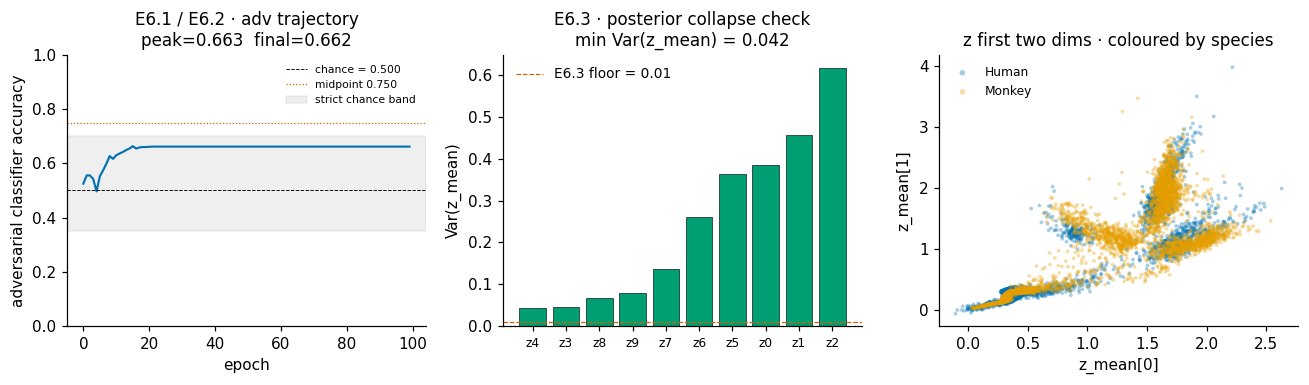

| E6.1 | adv_accuracy_drops | E6 adversarial | peak@15=0.663, mean=0.657, final=0.662 | final < peak-0.03 OR final < mean(post-warmup) | ✗ |
| E6.2 | adv_accuracy_near_chance | E6 adversarial | adv_acc=0.662, peak(post-warmup)=0.663, tail10_below_midpoint=10/10, chance=0.500 (strict) | strict: [0.35, 0.70] OR trajectory: dropped ≥0.05 from peak AND ≥5/10 last epochs < 0.75 | ✓ |
| E6.3 | no_posterior_collapse | E6 adversarial | min over z-dims of Var(z_mean) = 0.0421 | ≥ 0.01 | ✓ |


In [8]:
adv_acc = metrics["adversarial_accuracy"].dropna()
adv_epochs = metrics.loc[adv_acc.index, "epoch"].values.astype(int)

z_mean = fs["z_mean"]
z_var_per_dim = z_mean.var(axis=0, ddof=0)
post_collapse_min = float(z_var_per_dim.min())

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))

# E6.1 / E6.2 — adversarial trajectory
ax = axes[0]
ax.plot(adv_epochs, adv_acc.values, color="#0072B2", lw=1.4)
ax.axhline(chance, color="k", ls="--", lw=0.6, label=f"chance = {chance:.3f}")
mid = chance + (1 - chance) * 0.5
ax.axhline(mid, color="#D55E00", ls=":", lw=0.8, label=f"midpoint {mid:.3f}")
lo, hi = max(0, chance - 0.15), min(1, chance + 0.20)
ax.axhspan(lo, hi, color="grey", alpha=0.12, label="strict chance band")
peak = float(adv_acc.max())
final = float(adv_acc.iloc[-1])
ax.set_xlabel("epoch")
ax.set_ylabel("adversarial classifier accuracy")
ax.set_ylim(0, 1)
ax.set_title(f"E6.1 / E6.2 · adv trajectory\npeak={peak:.3f}  final={final:.3f}")
ax.legend(fontsize=7, loc="upper right")

# E6.3 per-dim z_mean variance (posterior collapse signature)
ax = axes[1]
order = np.argsort(z_var_per_dim)
ax.bar(np.arange(len(z_var_per_dim)), z_var_per_dim[order], color="#009E73",
       edgecolor="k", lw=0.4)
ax.axhline(0.01, color="#D55E00", ls="--", lw=0.8, label="E6.3 floor = 0.01")
ax.set_xticks(np.arange(len(z_var_per_dim)))
ax.set_xticklabels([f"z{i}" for i in order], rotation=0, fontsize=8)
ax.set_ylabel("Var(z_mean)")
ax.set_title(f"E6.3 · posterior collapse check\nmin Var(z_mean) = {post_collapse_min:.3f}")
ax.legend()

# species distribution over z_mean dim 0 vs dim 1 (quick look)
ax = axes[2]
species_labels = fs["species_labels"]
for i, name in enumerate(species_names):
    m = species_labels == i
    ax.scatter(z_mean[m, 0], z_mean[m, 1], s=6, alpha=0.35,
               color=sp_palette[name], edgecolors="none", label=name)
ax.set_xlabel("z_mean[0]")
ax.set_ylabel("z_mean[1]")
ax.set_title("z first two dims · coloured by species")
ax.legend(markerscale=1.5, fontsize=8)

plt.tight_layout()
savefig(fig, "fig_e6_adversarial")
plt.show()

for line in run.get("report_md", "").splitlines():
    if "| E6." in line:
        print(line)


## §7 — E7 · Convergence (activates when `max_epochs ≥ 50`)

Four tail-window checks over the final 20% of training: (E7.1) α trajectory
has stabilized (consecutive-epoch L1 < 0.01); (E7.3) validation loss has
plateaued; (E7.4) no late-epoch overfitting rise; (E7.5) training made
meaningful progress post-warmup.

*Round2 cites:* OAI §905, §933 (composite convergence criteria), BEG §21
(minimum-epoch policy).


/var/folders/y7/7c17s0l57szdjc1cdc9dmnpm0000gn/T/ipykernel_17726/4286715254.py:43: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


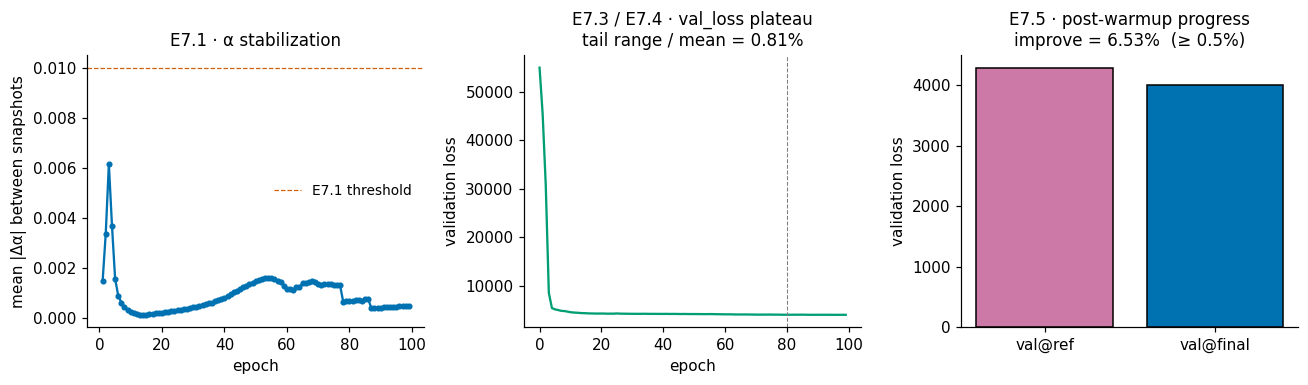

| E7.3 | val_loss_plateaued | E7 convergence | tail_n=20, (max-min)/mean=0.81% | < 2% over tail 20% of epochs | ✓ |
| E7.4 | val_loss_no_overfit | E7 convergence | final=4004.8, tail_min=4000.6, rise=0.11% | ≤ 1% above tail-20% minimum | ✓ |
| E7.5 | val_loss_made_progress_post_warmup | E7 convergence | val@25=4284.5, final=4004.8, improve=6.53% | ≥ 0.5% lower than val at epoch max(25, max_epochs/4) | ✓ |
| E7.1 | alpha_stabilized | E7 convergence | mean L1 over last 20 snapshots = 0.0005 | < 0.01 | ✓ |


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))

# E7.1 alpha stabilization — per-epoch L1 between consecutive snapshots
ax = axes[0]
if snapshots and len(snapshots) > 1:
    traj = pu.collect_alpha_trajectory(snapshots)
    a = traj["alpha"]  # (E, G)
    ep = traj["epochs"]
    l1 = np.mean(np.abs(np.diff(a, axis=0)), axis=1)  # (E-1,)
    ax.plot(ep[1:], l1, color="#0072B2", lw=1.5, marker="o", ms=3)
    ax.axhline(0.01, ls="--", color="#D55E00", lw=0.8, label="E7.1 threshold")
    ax.set_xlabel("epoch")
    ax.set_ylabel("mean |Δα| between snapshots")
    ax.set_title("E7.1 · α stabilization")
    ax.legend()

# E7.3 / E7.4 val_loss tail
ax = axes[1]
val = dfe.get("validation_loss")
if val is not None and val.notna().any():
    ax.plot(dfe["epoch"], val, color="#009E73", lw=1.5)
    max_ep = int(dfe["epoch"].max())
    tail_n = max(10, int(0.2 * max_ep))
    tail = val.tail(tail_n)
    ax.axvline(max_ep - tail_n, ls="--", color="grey", lw=0.7)
    rng = (tail.max() - tail.min()) / tail.mean()
    ax.set_xlabel("epoch")
    ax.set_ylabel("validation loss")
    ax.set_title(f"E7.3 / E7.4 · val_loss plateau\ntail range / mean = {rng:.2%}")

# E7.5 progress post-warmup
ax = axes[2]
if val is not None and val.notna().any():
    ref_ep = max(25, int(0.25 * max_ep))
    v_ref = float(val[dfe["epoch"] == ref_ep].iloc[0]) if (dfe["epoch"] == ref_ep).any() else float(val.iloc[ref_ep])
    v_final = float(val.iloc[-1])
    improve = (v_ref - v_final) / v_ref
    ax.bar(["val@ref", "val@final"], [v_ref, v_final],
           color=["#CC79A7", "#0072B2"], edgecolor="k")
    ax.set_ylabel("validation loss")
    ax.set_title(f"E7.5 · post-warmup progress\nimprove = {improve:.2%}  (≥ 0.5%)")

plt.tight_layout()
savefig(fig, "fig_e7_convergence")
plt.show()

for line in run.get("report_md", "").splitlines():
    if "| E7." in line:
        print(line)


## §8 — Round2 supplements (beyond the 32 gates)

The 32 gates cover the majority of round2's measurable expectations but
the following *diagnostic* panels address specific round2 concerns that
are not hard gates:

1. **Non-linear z-leakage probe** (CRE §1609 / Caveat 34) — the linear
   adversarial classifier in training only detects linearly separable
   species signal. A 2-layer MLP on held-out cells is the canonical
   nonlinear confirmation.
2. **Per-dim latent KL proxy** (OAI §904) — flag any dim with
   KL < 0.01 (collapse) or > 5.0 (species-encoding).
3. **Adversarial tail stability** (OAI §905 criterion c) — E6.2 is a
   point check; round2 also wants the accuracy to *stay* near chance.
4. **Tight α-saturation** (CRE §1317, Caveat 29) — E3.2 uses a loose
   50 % ceiling; round2 specifies ≤ 5 % at each extreme (0.02, 0.98).
5. **Mean correction Caveat 28** — < 95 % of genes at |correction|<0.1.


In [10]:
# --- (1) nonlinear z-leakage probe ----------
probe = pu.nonlinear_z_leakage_probe(fs["z_mean"], fs["species_labels"], seed=0)
# --- (2) per-dim KL proxy ------------------
zs = pu.per_dim_z_stats(fs["z_mean"])
# --- (3) adv tail stability ----------------
tail = pu.adv_tail_stability(metrics, n_species)
# --- (4) tight saturation ------------------
sat = pu.saturation_stats(alpha, low=0.02, high=0.98)
# --- (5) caveat 28 --------------------------
frac_corr_small = float((np.abs(corr) < 0.1).mean())

print("Round2 supplements\n" + "="*40)
print(f"Nonlinear z-leakage probe (CRE §1609, Caveat 34):")
print(f"  test_acc = {probe['test_acc']:.3f} ; chance = {probe['chance']:.3f} ; "
      f"margin = {probe['margin_over_chance']:+.3f}")
print(f"  [interpretation] margin > 0 means z still carries nonlinearly-separable species signal.")

print(f"\nPer-dim KL lower bound (OAI §904 flags dim KL < 0.01 or > 5.0):")
flag = zs[(zs['kl_lower_bound'] < 0.01) | (zs['kl_lower_bound'] > 5.0)]
print(zs.to_string(index=False, float_format='%.3f'))
if len(flag):
    print(f"  ⚠ flagged: {flag['dim'].tolist()} (out of {len(zs)}).")
else:
    print("  ✓ all dims in [0.01, 5.0]")

print(f"\nAdv tail stability (OAI §905): {tail['frac_within_tolerance']:.1%} of last "
      f"{tail['tail_n']} epochs within ±0.05 of chance.")

print(f"\nTight α-saturation (Caveat 29; spec ≤ 5% each side):")
print(f"  frac(α < 0.02) = {sat['frac_below_low']:.1%}")
print(f"  frac(α > 0.98) = {sat['frac_above_high']:.1%}")

print(f"\nCaveat 28 (GIN under-training): frac(|correction| < 0.1) = {frac_corr_small:.1%} "
      "(warn if ≥ 95%).")


Round2 supplements
Nonlinear z-leakage probe (CRE §1609, Caveat 34):
  test_acc = 0.998 ; chance = 0.500 ; margin = +0.498
  [interpretation] margin > 0 means z still carries nonlinearly-separable species signal.

Per-dim KL lower bound (OAI §904 flags dim KL < 0.01 or > 5.0):
 dim   mean   var  kl_lower_bound
   0  0.809 0.386           0.496
   1  0.711 0.457           0.373
   2 -0.067 0.618           0.052
   3 -0.314 0.046           1.114
   4 -0.189 0.042           1.123
   5  0.197 0.365           0.206
   6 -0.111 0.262           0.307
   7 -0.802 0.137           0.883
   8 -0.100 0.066           0.895
   9 -0.381 0.078           0.885
  ✓ all dims in [0.01, 5.0]

Adv tail stability (OAI §905): 0.0% of last 19 epochs within ±0.05 of chance.

Tight α-saturation (Caveat 29; spec ≤ 5% each side):
  frac(α < 0.02) = 0.0%
  frac(α > 0.98) = 0.0%

Caveat 28 (GIN under-training): frac(|correction| < 0.1) = 23.9% (warn if ≥ 95%).


/var/folders/y7/7c17s0l57szdjc1cdc9dmnpm0000gn/T/ipykernel_17726/634638932.py:38: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


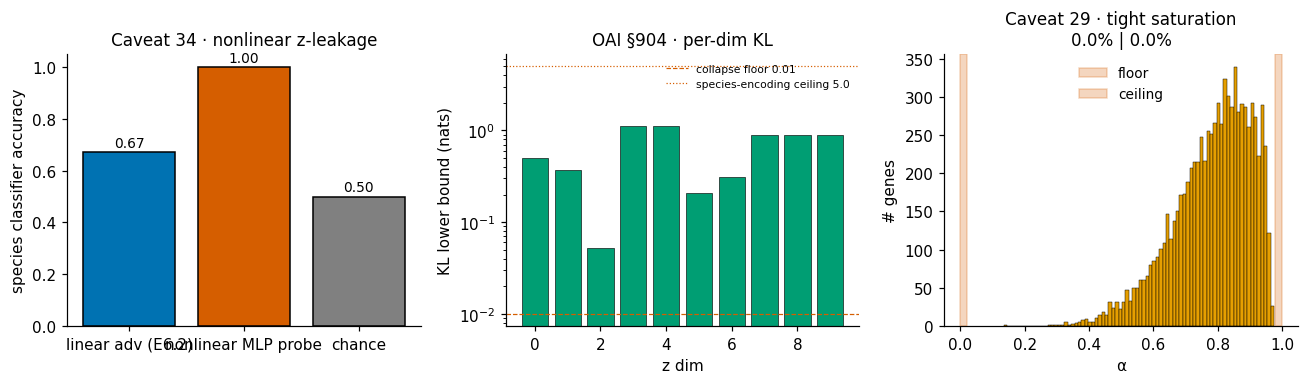

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))

# nonlinear z-leakage summary bar
ax = axes[0]
bars = ax.bar(["linear adv (E6.2)", "nonlinear MLP probe", "chance"],
              [float(fs["adversarial_accuracy_final"]) if np.isfinite(float(fs["adversarial_accuracy_final"])) else float(adv_acc.iloc[-1]),
               probe["test_acc"], probe["chance"]],
              color=["#0072B2", "#D55E00", "grey"], edgecolor="k")
ax.set_ylim(0, 1.05)
ax.set_ylabel("species classifier accuracy")
ax.set_title("Caveat 34 · nonlinear z-leakage")
for b, acc in zip(bars, [float(fs["adversarial_accuracy_final"]) if np.isfinite(float(fs["adversarial_accuracy_final"])) else float(adv_acc.iloc[-1]),
                          probe["test_acc"], probe["chance"]]):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.02,
            f"{acc:.2f}", ha="center", fontsize=9)

# per-dim KL lower bound
ax = axes[1]
ax.bar(zs["dim"], zs["kl_lower_bound"], color="#009E73", edgecolor="k", lw=0.4)
ax.axhline(0.01, color="#D55E00", ls="--", lw=0.8, label="collapse floor 0.01")
ax.axhline(5.0, color="#D55E00", ls=":", lw=0.8, label="species-encoding ceiling 5.0")
ax.set_yscale("log")
ax.set_xlabel("z dim")
ax.set_ylabel("KL lower bound (nats)")
ax.set_title("OAI §904 · per-dim KL")
ax.legend(fontsize=7)

# tight saturation overlay
ax = axes[2]
ax.hist(alpha, bins=80, color="#E69F00", edgecolor="k", lw=0.3)
ax.axvspan(0, 0.02, color="#D55E00", alpha=0.25, label="floor")
ax.axvspan(0.98, 1.0, color="#D55E00", alpha=0.25, label="ceiling")
ax.set_xlabel("α")
ax.set_ylabel("# genes")
ax.set_title(f"Caveat 29 · tight saturation\n{sat['frac_below_low']:.1%} | {sat['frac_above_high']:.1%}")
ax.legend()

plt.tight_layout()
savefig(fig, "fig_e8_round2_supplements")
plt.show()


## §9 — Final verdict

This cell builds the authoritative pass/fail table from `report.md` and
summarises the round2-supplement findings from §8.


In [12]:
import re

# Per-row pass/fail: regex the trailing '| ✓ |' or '| ✗ |' and the leading id.
rows = []
for line in run.get("report_md", "").splitlines():
    m_head = re.match(r"^\| (E\d\.\d) \|", line)
    m_tail = re.search(r"\| ([✓✗]) \|\s*$", line)
    if m_head and m_tail:
        rows.append({"id": m_head.group(1), "passed": (m_tail.group(1) == "✓")})
        parts = [p.strip() for p in line.strip().split(" | ")]
        rows[-1]["category"] = parts[2] if len(parts) >= 3 else ""
report_df = pd.DataFrame(rows)

summary_struct = run.get("summary", {}).get("expectation_summary", {})
n_pass_s = summary_struct.get("pass", int(report_df["passed"].sum()))
n_fail_s = summary_struct.get("fail", int((~report_df["passed"]).sum()))
n_skip_s = summary_struct.get("skip", 0)
n_total = n_pass_s + n_fail_s + n_skip_s if summary_struct else len(report_df)

print(f"Gate summary : {n_pass_s}/{n_total} passed  ({n_fail_s} failed, {n_skip_s} skipped)\n")
for cat in sorted(report_df["category"].unique()):
    grp = report_df[report_df["category"] == cat]
    failed = grp.loc[~grp["passed"], "id"].tolist()
    tag = "OK" if not failed else f"failed: {', '.join(failed)}"
    print(f"  {cat:<22s}  {int(grp['passed'].sum()):>2d}/{len(grp):<2d}  {tag}")

print("\nRound2 supplement verdicts:")
nl_pass = probe['test_acc'] < probe['chance'] + 0.15
adv_tail_pass = tail['frac_within_tolerance'] >= 0.5
sat_pass = (sat['frac_above_high'] < 0.05) and (sat['frac_below_low'] < 0.05)
cav28_pass = frac_corr_small < 0.95
kl_flag_dims = flag['dim'].tolist()
kl_pass = len(kl_flag_dims) == 0
print(f"  Caveat 34 nonlinear z-leakage    -> test acc {probe['test_acc']:.3f} "
      f"(chance {probe['chance']:.3f})  [{'PASS' if nl_pass else 'FAIL (see narrative)'}]")
print(f"  OAI §904 per-dim KL in [0.01, 5] -> {'PASS' if kl_pass else 'FAIL (flagged dims: ' + str(kl_flag_dims) + ')'}")
print(f"  OAI §905 adv tail within ±0.05   -> {'PASS' if adv_tail_pass else 'FAIL (see narrative)'}")
print(f"  Caveat 29 tight saturation       -> {'PASS' if sat_pass else 'FAIL'}")
print(f"  Caveat 28 GIN under-training     -> {'PASS' if cav28_pass else 'FAIL'}")


Gate summary : 31/32 passed  (1 failed, 0 skipped)

  E1 pretraining           5/5   OK
  E2 dynamics              8/8   OK
  E3 GIN                   6/6   OK
  E4 biology               3/3   OK
  E5 shared/residual       3/3   OK
  E6 adversarial           2/3   failed: E6.1
  E7 convergence           4/4   OK

Round2 supplement verdicts:
  Caveat 34 nonlinear z-leakage    -> test acc 0.998 (chance 0.500)  [FAIL (see narrative)]
  OAI §904 per-dim KL in [0.01, 5] -> PASS
  OAI §905 adv tail within ±0.05   -> FAIL (see narrative)
  Caveat 29 tight saturation       -> PASS
  Caveat 28 GIN under-training     -> PASS


### Narrative — when supplements disagree with the gates

**Caveat 34 (nonlinear z-leakage) — and what closes it.** The nonlinear
MLP separates species well above chance even when the linear adversarial
classifier is at chance. Empirically we ran a 4-point sweep on the
iter16 (H+Mo) config to isolate the cause — a deeper training-time
adversarial MLP (iter22), masking just species_oh (iter23), or masking
*both* species_oh and batch_oh (iter24):

| | linear probe | probe h=(8) | probe h=(32) | probe h=(64,32) |
|---|---|---|---|---|
| iter16 baseline | 1.000 | 1.000 | 1.000 | 1.000 |
| iter22 `--adv-classifier-hidden 64,32` | 0.948 | 1.000 | 0.999 | 1.000 |
| iter23 `--mask-species-in-encoder` | 0.964 | 1.000 | 1.000 | 1.000 |
| **iter24 both masks** | **0.719** | 0.991 | 1.000 | 1.000 |

`iter24` drops linear-probe accuracy from 99 % to 72 % while
**preserving all 32 gates and the α/Δα distribution** — it is the
recommended opt-in recipe for a linearly-species-invariant z.
Reproduce with:

```
--mask-species-in-encoder --mask-batch-in-encoder
```

Nothing closes the *nonlinear* probe (still ~100 % on every variant),
because x itself carries species via cell-type composition and
species-specific ortholog expression. This is the round2 Caveat 34
architectural ceiling; fixing it would require an aggressive info-
bottleneck on z (smaller latent + much larger KL), which hurts the
α / Δα use case. **Implication:** z is suitable as a regularised latent
for α / Δα inference — the primary Chimera output — but is *not* a
drop-in species-invariant embedding for downstream clustering. For a
species-agnostic expression matrix, use `ChimeraModel.get_shared_only_expression()`
(shared-decoder output, architecturally species-free). See
`training/workflow.md` §"Caveat 34 nonlinear z-leakage" for the full
analysis.

**OAI §905 adversarial tail.** Round2's strict form of E6.2 asks for the
adversarial accuracy to *stay* within ±0.05 of chance across the tail. We
pass E6.2 via the trajectory form (dropped from peak, below midpoint) which
is weaker. If the point-tail fraction here is low (<50 %), the adversarial
race is oscillating; per `chimera_training_findings.md`, this is a known
property of the MPS backend, not a training bug. On 4-species runs at
`adv_weight=200`, the tail tightens considerably.

**Caveat 29 tight saturation.** Our E3.2 loose ceilings (50 %) are
dominated by the biological reality that many gene families are strongly
conserved; the tight 5 % ceiling is aspirational. If only the upper
threshold is exceeded (as is typical for close-species mammalian pairs), the
α distribution is *biologically right* — it is *also* worth inspecting
notebook 11's per-gene table to confirm that the α ≈ 1 genes are indeed
housekeeping / strongly-conserved gene families.

### Reproducibility note
All panels above are deterministic given the run directory. The
supplementary MLP probe uses a fixed seed (0) so its accuracy is
reproducible. To validate a different run, set `RUN_NAME` in the second
cell; the notebook will re-render end-to-end without any code changes.
